# Домашнее задание. Поиск общих ключевых точек на нескольких изображениях

Дано несколько изображений организмов одного типа:
https://drive.google.com/drive/folders/1SkIjE_XUW9CAFDfQutDJrzoZlPh1JMfm?usp=sharing
Необходимо определить ключевые точки, которые соответствуют одним и тем же локальным особенностям объекта на разных изображениях.

Проект выполнялся в среде разработки Google Colab.

Выбранный метод SIFT (для сравнения по числу точек также ORB).

GitHub репозиторий: https://github.com/leonid6011/hw2_krylasov_cv

## 1. Загрузка и подготовка

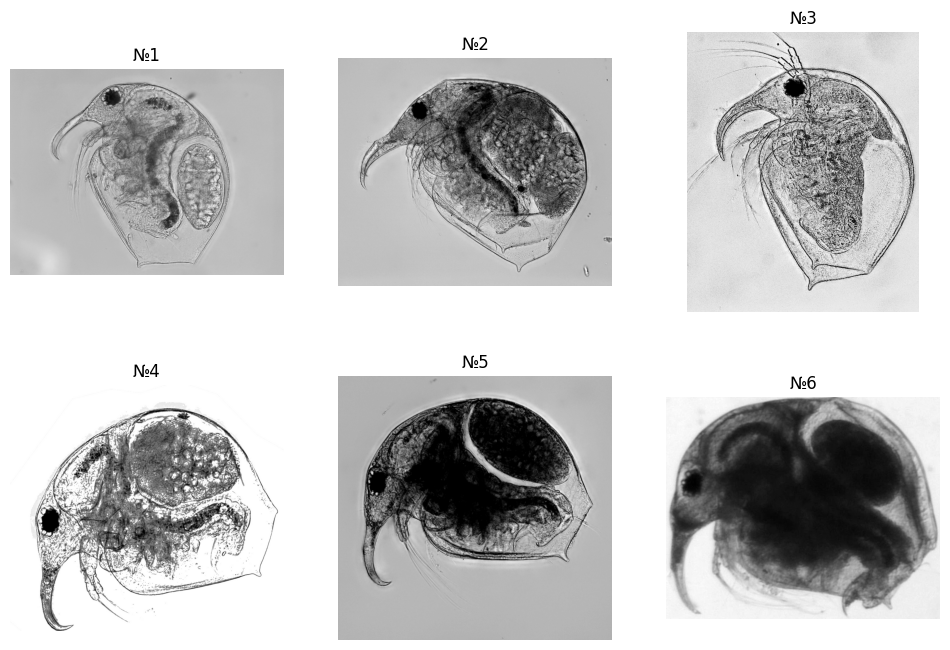

In [139]:
import os, glob, zipfile
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd

# распаковка загруженного архива
for z in glob.glob("*.zip"):
  zipfile.ZipFile(z).extractall("data")
files = sorted(glob.glob("data/**/*.jpg", recursive=True))

# длинная сторона после масштабирования в пикселях
SIZE = 800
# изображения 2, 3, 5 рачок повернут другим боком
FLIP = [1, 2, 4]

imgs = []
for i, f in enumerate(files):
  img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
  k = SIZE / max(img.shape)
  img = cv2.resize(img, None, fx=k, fy=k)
  if i in FLIP:
    img = np.fliplr(img).copy()
  imgs.append(img)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, (ax, img) in enumerate(zip(axes.ravel(), imgs)):
  ax.imshow(img, cmap="gray")
  ax.set_title(f"№{i + 1}")
  ax.axis("off")
plt.show()

Снимки переведены в оттенки серого так как SIFT работает с яркостью, цвет ему не нужен. Все снимки приведены к одному размеру, длинная сторона 800 пикселей, так как они сделаны с разным увеличением, от 778 до 3005 пикселей по ширине. Снимки №2, №3, №5 отражены по горизонтали, на них рачок повёрнут к камере другим боком, а SIFT устойчив к повороту, но не к зеркальному отражению.

## 2. Ключевые точки и дескрипторы

In [140]:
# поиск точек
sift = cv2.SIFT_create()
# точки и дескрипторы SIFT для каждого снимка
kps, descs = [], []
for img in imgs:
  kp, des = sift.detectAndCompute(img, None)
  kps.append(kp)
  descs.append(des)

# для сравнения смотрим сколько точек находит метод ORB
methods = {
    "SIFT": cv2.SIFT_create(),
    "ORB": cv2.ORB_create(nfeatures=5000),
}
table = {name: [len(det.detect(img, None)) for img in imgs] for name, det in methods.items()}
pd.DataFrame(table, index=[f"№{i + 1}" for i in range(len(imgs))]).T

,№1,№2,№3,№4,№5,№6
SIFT,2530,4488,3738,7326,4150,107
ORB,4854,5000,5000,5000,5000,35


In [141]:
# сколько точек SIFT находит на снимках исходного размера, без уменьшения
rows = []
for i, f in enumerate(files):
  orig = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
  n = len(cv2.SIFT_create().detect(orig, None))
  rows.append([f"№{i + 1}", f"{orig.shape[1]}×{orig.shape[0]}", n, len(kps[i])])
pd.DataFrame(rows, columns=["снимок", "исходный размер", "точек до уменьшения", "точек после сжатия"])

,снимок,исходный размер,точек до уменьшения,точек после сжатия
0,№1,2592×1944,15395,2530
1,№2,3005×2513,36728,4488
2,№3,1608×1944,53257,3738
3,№4,1959×1760,27192,7326
4,№5,2170×2094,15098,4150
5,№6,778×632,115,107


На снимках исходного размера SIFT находит десятки тысяч точек, например на третьем снимке 53257 точек, в основном на мелких деталях и шуме. Поэтому снимки приведены к 800 пикселям по длинной стороне.

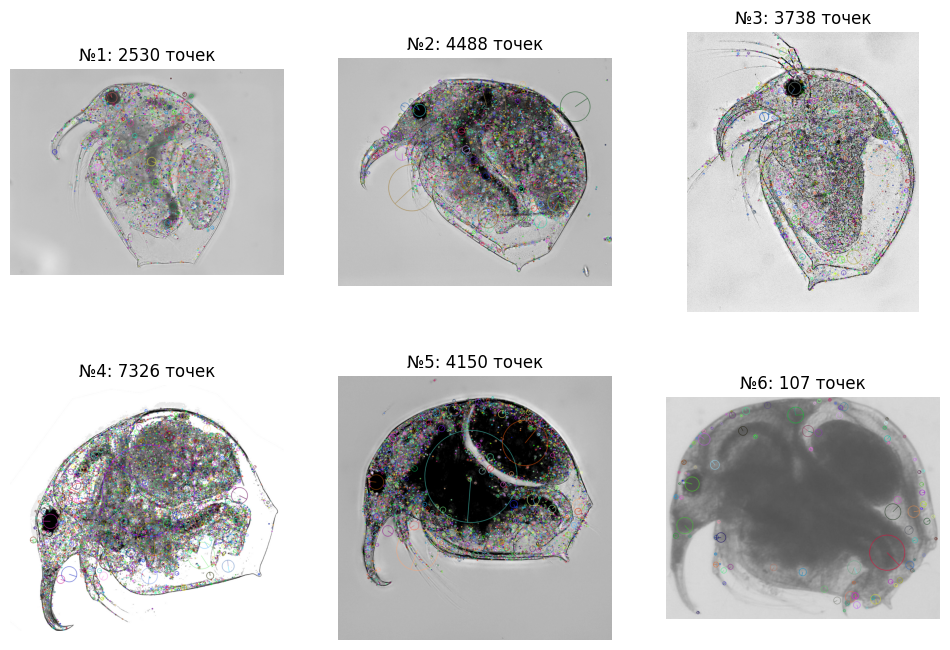

In [142]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, (ax, img, kp) in enumerate(zip(axes.ravel(), imgs, kps)):
  vis = cv2.drawKeypoints(img, kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
  ax.imshow(vis)
  ax.set_title(f"№{i + 1}: {len(kp)} точек")
  ax.axis("off")
plt.show()

SIFT ищет точки на разных масштабах, экстремумы разности гауссианов, и описывает окрестность каждой точки 128 числами, гистограммами направлений градиента, построенными относительно направления самой точки. Поэтому дескриптор устойчив к повороту и масштабу. На рисунке размер круга это масштаб точки, линия это её направление.

Число точек сильно зависит от снимка: на чётком снимке с выраженной текстурой №4 их 7326, на маленьком и размытом №6 их всего 107. ORB для сравнения на большинстве снимков находит больше точек (до 5000, это ограничение параметра nfeatures), но на снимке №4 меньше, чем SIFT (5000 против 7326), а на размытом №6 только 35.

## 3. Параметры SIFT

|Параметр|По умолчанию|Что делает|
|---|---|---|
|nfeatures|0 (все)|сколько лучших точек оставить|
|nOctaveLayers|3|число слоев в каждой октаве пирамиды масштабов, если больше, то точнее по масштабу, больше точек|
|contrastThreshold|0.04|порог контраста, точки со слабым контрастом отбрасываются, больше порог - меньше точек|
|edgeThreshold|10|отсев точек, лежащих на прямых краях  тк они плохо локализуются, больше значит меньше отсеивается|
|sigma|1.6|размытие исходного изображения если больше то меньше мелких точек, шум влияет меньше|

Эксперимент. Как понять, какие параметры лучше? Возьмём снимок №2 и его копию, повёрнутую на 30 градусов и уменьшенную до 0.8. Преобразование известно, поэтому можно проверить, какие совпадения верные. Точка с первого снимка после поворота должна попасть в найденную пару на втором.

In [143]:
def lowe_matches(des1, des2, ratio=0.75):
    """Сопоставление с тестом Лоу, оставляем пару, если лучший сосед заметно лучше второго."""
    bf = cv2.BFMatcher(cv2.NORM_L2)
    good = []
    for m, n in bf.knnMatch(des1, des2, k=2):
        if m.distance < ratio * n.distance:
            good.append(m)
    return good

# тестовая пара снимок №2 и его копия с поворотом 30 град и масштабом 0.8
test = imgs[1]
h, w = test.shape
M = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 0.8)
test_rot = cv2.warpAffine(test, M, (w, h), borderValue=int(np.median(test)))

def test_params(**params):
    sift = cv2.SIFT_create(**params)
    n_points = np.mean([len(sift.detect(im, None)) for im in imgs])   # среднее по 6 снимкам
    kp1, d1 = sift.detectAndCompute(test, None)
    kp2, d2 = sift.detectAndCompute(test_rot, None)
    good = lowe_matches(d1, d2)
    correct = 0
    for m in good:
        p = M @ [*kp1[m.queryIdx].pt, 1]          # куда должна попасть точка после поворота
        if np.linalg.norm(p - kp2[m.trainIdx].pt) < 5:
            correct += 1
    return round(n_points), len(good), correct

In [144]:
experiments = {
    "contrastThreshold": [0.02, 0.04, 0.08, 0.16],
    "edgeThreshold":     [5, 10, 20],
    "sigma":             [1.2, 1.6, 2.4],
    "nOctaveLayers":     [2, 3, 5],
    "nfeatures":         [500, 1000, 0],
}
rows = []
for param, values in experiments.items():
    for v in values:
        n, good, correct = test_params(**{param: v})
        rows.append([param, v, n, good, correct, f"{100 * correct / max(good, 1):.0f}%"])

pd.DataFrame(rows, columns=["параметр", "значение", "точек (среднее)",
                            "совпадений", "верных", "доля верных"])

,параметр,значение,точек (среднее),совпадений,верных,доля верных
0,contrastThreshold,0.02,4223,2053,2047,100%
1,contrastThreshold,0.04,3723,1946,1940,100%
2,contrastThreshold,0.08,2552,1204,1202,100%
3,contrastThreshold,0.16,917,103,98,95%
4,edgeThreshold,5.00,3148,1639,1631,100%
5,edgeThreshold,10.00,3723,1946,1940,100%
6,edgeThreshold,20.00,3951,2064,2054,100%
7,sigma,1.20,6722,3348,3329,99%
8,sigma,1.60,3723,1946,1940,100%
9,sigma,2.40,1493,878,874,100%


Доля верных совпадений почти везде 99 - 100 %, то есть параметры меняют в основном число точек, а не качество сопоставления.

contrastThreshold: при 0.16 точек в 4 раза меньше,  совпадений в 19 раз меньше, доля верных падает до 95 %.

sigma: при 1.2 точек почти вдвое больше, при 2.4 в 2.5 раза меньше.

nOctaveLayers и edgeThreshold: чем больше значение, тем больше точек.

nfeatures просто ограничивает число точек.

Значения по умолчанию дают хороший баланс между числом точек и надёжностью, поэтому дальше используются они.

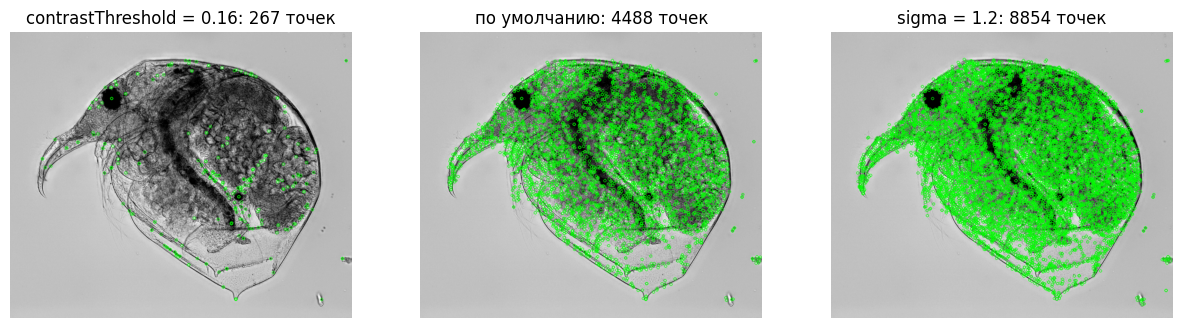

In [145]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
variants = [("contrastThreshold = 0.16", dict(contrastThreshold=0.16)),
            ("по умолчанию", {}), ("sigma = 1.2", dict(sigma=1.2))]
for ax, (name, p) in zip(axes, variants):
  kp = cv2.SIFT_create(**p).detect(imgs[1], None)
  ax.imshow(cv2.drawKeypoints(imgs[1], kp, None, color=(0, 255, 0)))
  ax.set_title(f"{name}: {len(kp)} точек")
  ax.axis("off")
plt.show()

При contrastThreshold = 0.16 остаётся 267 точек, в основном у глаза и вдоль кишечника. По умолчанию стоит 4488 и точки покрывают всё тело. При sigma = 1.2 их 8854, добавляется самая мелкая текстура.

## 4. Сопоставление между снимками

In [146]:
def match_pair(i, j, K, D, ratio=0.75, min_inliers=6):
    good = lowe_matches(D[i], D[j], ratio)
    back = {m.queryIdx: m.trainIdx for m in lowe_matches(D[j], D[i], ratio)}
    mutual = [m for m in good if back.get(m.trainIdx) == m.queryIdx]
    if len(mutual) < 3:
        return good, mutual, []
    p1 = np.float32([K[i][m.queryIdx].pt for m in mutual])
    p2 = np.float32([K[j][m.trainIdx].pt for m in mutual])
    M, mask = cv2.estimateAffinePartial2D(p1, p2, method=cv2.RANSAC, ransacReprojThreshold=10)
    if M is None or mask.sum() < min_inliers:
        return good, mutual, []
    inliers = [m for m, ok in zip(mutual, mask.ravel()) if ok]
    return good, mutual, inliers

rows = []
for j in range(1, len(imgs)):
    good, mutual, inliers = match_pair(0, j, kps, descs)
    rows.append([f"№1 – №{j + 1}", len(good), len(mutual), len(inliers)])
pd.DataFrame(rows, columns=["пара", "после теста Лоу", "после взаимной проверки", "после RANSAC"])

,пара,после теста Лоу,после взаимной проверки,после RANSAC
0,№1 – №2,10,3,0
1,№1 – №3,5,2,0
2,№1 – №4,5,3,0
3,№1 – №5,13,6,0
4,№1 – №6,57,0,0


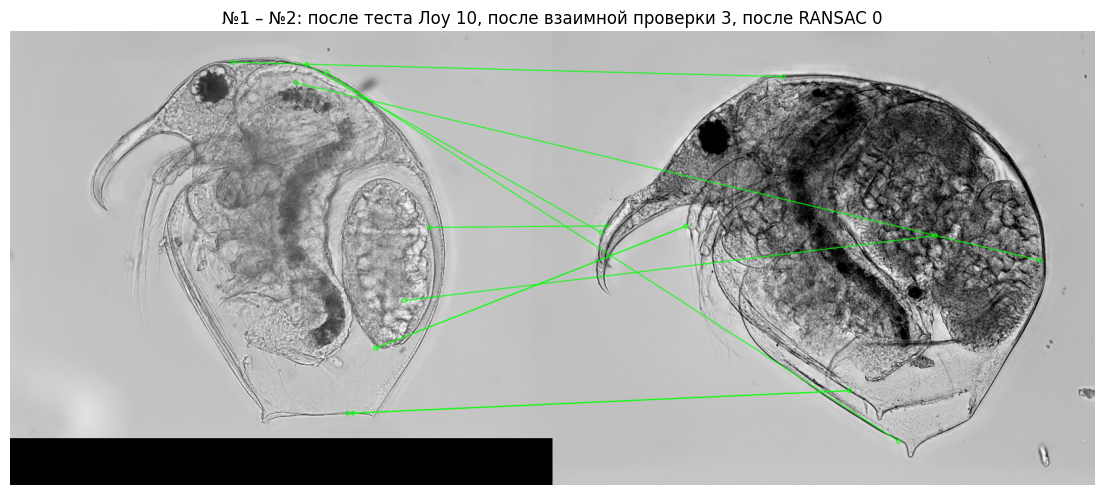

In [147]:
good, mutual, inliers = match_pair(0, 1, kps, descs)
vis = cv2.drawMatches(imgs[0], kps[0], imgs[1], kps[1], good, None,
                      matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(14, 6)); plt.imshow(vis); plt.axis("off")
plt.title(f"№1 – №2: после теста Лоу {len(good)}, после взаимной проверки {len(mutual)}, "
          f"после RANSAC {len(inliers)}")
plt.show()

После теста Лоу между разными особями остаются единицы совпадений. Взаимная проверка убирает почти все, например в паре №1 - №6 все 57, они сходились к одной точке. RANSAC не находит преобразования, с которым согласны хотя бы 6 пар, поэтому надёжных совпадений нет. На рисунке видно, что линии соединяют разные части тела, то есть совпадения случайные. Причина в том, что у разных особей разная внутренняя текстура, а дескрипторы описывают именно её.

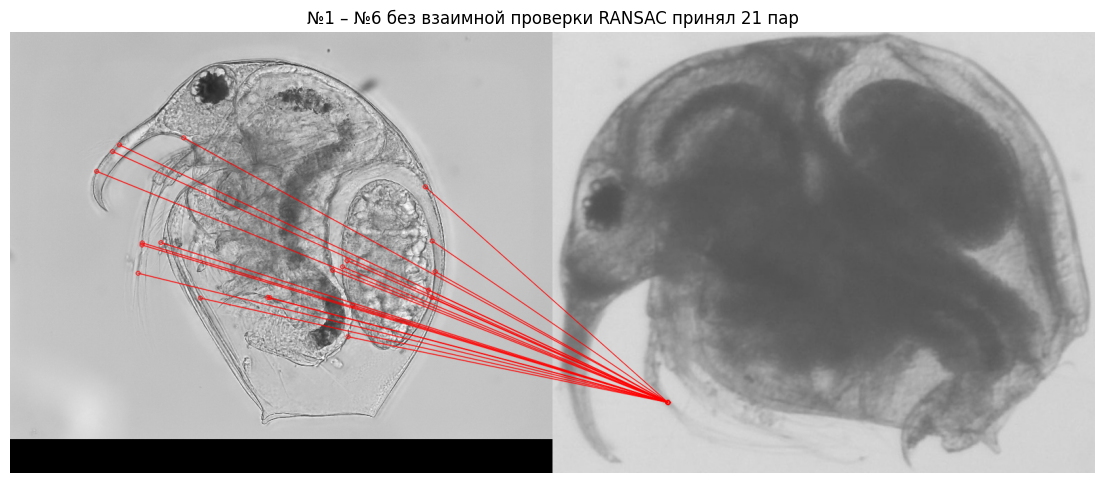

In [148]:
# первый вариант фильтрации тест Лоу + RANSAC, без взаимной проверки
good16 = lowe_matches(descs[0], descs[5])
p1 = np.float32([kps[0][m.queryIdx].pt for m in good16])
p2 = np.float32([kps[5][m.trainIdx].pt for m in good16])
A, mask16 = cv2.estimateAffinePartial2D(p1, p2, method=cv2.RANSAC, ransacReprojThreshold=10)
bad = [m for m, ok in zip(good16, mask16.ravel()) if ok]
vis = cv2.drawMatches(imgs[0], kps[0], imgs[5], kps[5], bad, None,
                      matchColor=(255, 0, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(14, 6)); plt.imshow(vis); plt.axis("off")
plt.title(f"№1 – №6 без взаимной проверки RANSAC принял {len(bad)} пар")
plt.show()

Без взаимной проверки RANSAC в паре №1 - №6 принял 21 пару, но все линии сходятся в одну точку, то есть совпадения ложные. Поэтому я добавил взаимную проверку,и после неё в этой паре совпадений не осталось.

## 5. Общие ключевые точки

Общая ключевая точка - это точка, для которой нашлось надёжное соответствие на всех изображениях.

Алгоритм:
1. Выбираем опорное изображение тут это будет снимок №1.
2. Сопоставляем его с каждым из остальных снимков.
3. Общими считаем те точки снимка №1, у которых есть пара на каждом из остальных снимков.
4. Лучшими считаем точки с наименьшей суммой расстояний между дескрипторами, то есть чем меньше расстояние, тем больше похожи окрестности точек.

In [149]:
def common_points(K, D, ref=0):
    links = {}
    for j in range(len(K)):
        if j != ref:
            _, _, inliers = match_pair(ref, j, K, D)
            links[j] = {m.queryIdx: (m.trainIdx, m.distance) for m in inliers}
    common = [q for q in range(len(K[ref])) if all(q in links[j] for j in links)]
    common.sort(key=lambda q: sum(links[j][q][1] for j in links))
    return [{ref: q, **{j: links[j][q][0] for j in links}} for q in common]

tracks_real = common_points(kps, descs)
print("Общих точек на всех 6 снимках:", len(tracks_real))

Общих точек на всех 6 снимках: 0


На шести снимках общих точек не найдено. И это ожидаемо, уже в разделе 4 после RANSAC ни одна пара снимков не дала надёжных совпадений. На снимках находятся разные особи. У них по-разному расположены яйца, кишечник и другие внутренние структуры, а дескриптор SIFT описывает именно эту локальную текстуру. Одинаковой у всех особей остаётся в основном форма тела, а форму локальные дескрипторы описывают плохо. Кроме того, снимки сделаны на разных микроскопах с разным освещением, а снимок №6 вообще сильно размыт и на нем всего 107 точек.

Чтобы проверить, что сам алгоритм работает правильно, применим его к снимкам одной и той же особи. Из снимка №2 сделаем 8 видов, в каждом будет меняться одно свойство: положение, ориентация, масштаб и качество. Преобразование каждого вида известно, поэтому можно проверить каждую найденную общую точку.

In [150]:
def make_view(img, angle=0, scale=1.0, shift=(0, 0), blur=0, noise=0, jpeg=100):
    """Копия снимка с известным преобразованием и/или ухудшением качества."""
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
    M[:, 2] += shift
    v = cv2.warpAffine(img, M, (w, h), borderValue=int(np.median(img)))
    if blur:
        v = cv2.GaussianBlur(v, (0, 0), blur)
    if noise:
        v = np.clip(v + np.random.normal(0, noise, v.shape), 0, 255).astype(np.uint8)
    if jpeg < 100:
        v = cv2.imdecode(cv2.imencode(".jpg", v, [cv2.IMWRITE_JPEG_QUALITY, jpeg])[1],
                         cv2.IMREAD_GRAYSCALE)
    return v, M

np.random.seed(0)
src = imgs[1]
VIEWS = {
    "исходный":     {},
    "сдвиг":        dict(shift=(80, 50)),
    "поворот 45 гр":  dict(angle=45),
    "поворот 90 гр":  dict(angle=90),
    "масштаб ×0.6": dict(scale=0.6),
    "масштаб ×1.5": dict(scale=1.5),
    "размытие":     dict(blur=2),
    "шум + JPEG":   dict(noise=10, jpeg=40),
}
views, Ms = [], []
for params in VIEWS.values():
    v, M = make_view(src, **params)
    views.append(v)
    Ms.append(M)
vnames = list(VIEWS)

vkps, vdescs = [], []
for v in views:
    kp, d = sift.detectAndCompute(v, None)
    vkps.append(kp)
    vdescs.append(d)

tracks = common_points(vkps, vdescs)

correct = 0
for tr in tracks:
    x, y = vkps[0][tr[0]].pt
    if all(np.linalg.norm(Ms[k] @ [x, y, 1] - vkps[k][tr[k]].pt) < 5 for k in tr):
        correct += 1
print(f"Общих точек на всех {len(views)} видах: {len(tracks)}, из них верных: {correct}")

Общих точек на всех 8 видах: 105, из них верных: 105


На 8 видах одной особи найдено 105 общих точек, и все 105 верные. Значит, сопоставление и поиск общих точек реализованы правильно, а отсутствие общих точек на шести исходных снимках объясняется данными то есть разные особи, а не ошибкой метода. Дальше общие точки визуализируем на этих видах, а по ним же оценим устойчивость SIFT к каждому виду изменений.

## 6. Визуализация общих точек

Показаны лучшие 30 общих точек на каждом виде. Точка с одним и тем же номером и цветом это одна и та же особенность объекта на всех изображениях.

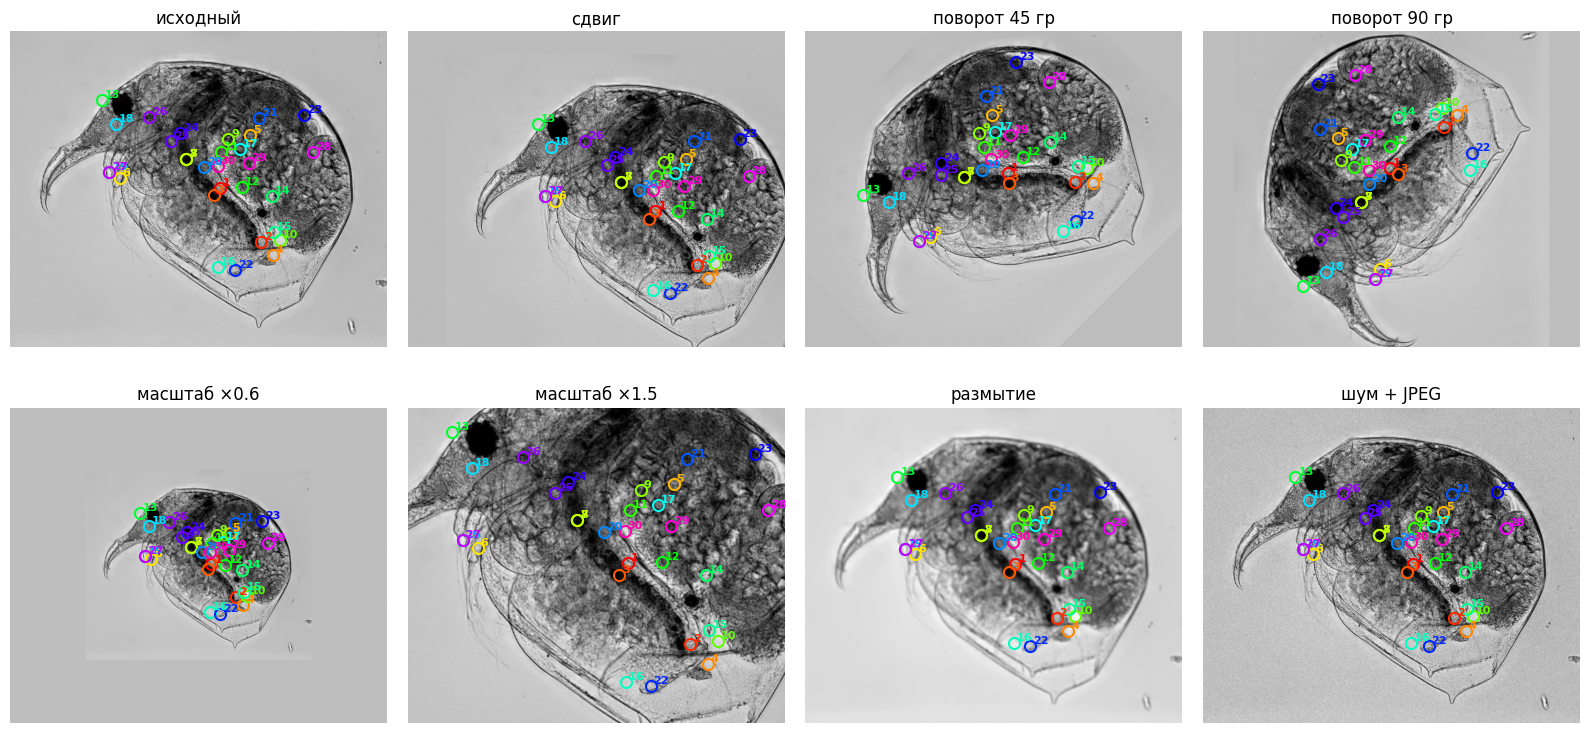

In [151]:
def show_common(images, K, tracks, titles, top=30, cols=4):
    """Лучшие общие точки на каждом изображении."""
    tracks = tracks[:top]
    colors = plt.cm.hsv(np.linspace(0, 0.9, len(tracks)))
    rows_n = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(4 * cols, 4 * rows_n))
    for k, ax in enumerate(axes.ravel()):
        ax.axis("off")
        if k >= len(images):
            continue
        ax.imshow(images[k], cmap="gray")
        ax.set_title(titles[k])
        for n, (tr, c) in enumerate(zip(tracks, colors), start=1):
            x, y = K[k][tr[k]].pt
            ax.plot(x, y, "o", mfc="none", mec=c, ms=8, mew=1.5)
            ax.text(x + 6, y - 6, str(n), color=c, fontsize=8, weight="bold")
    plt.tight_layout()
    plt.show()

show_common(views, vkps, tracks, vnames)

Чтобы сравнить расположение точек, поставим несколько видов рядом и соединим одну и ту же точку линией.

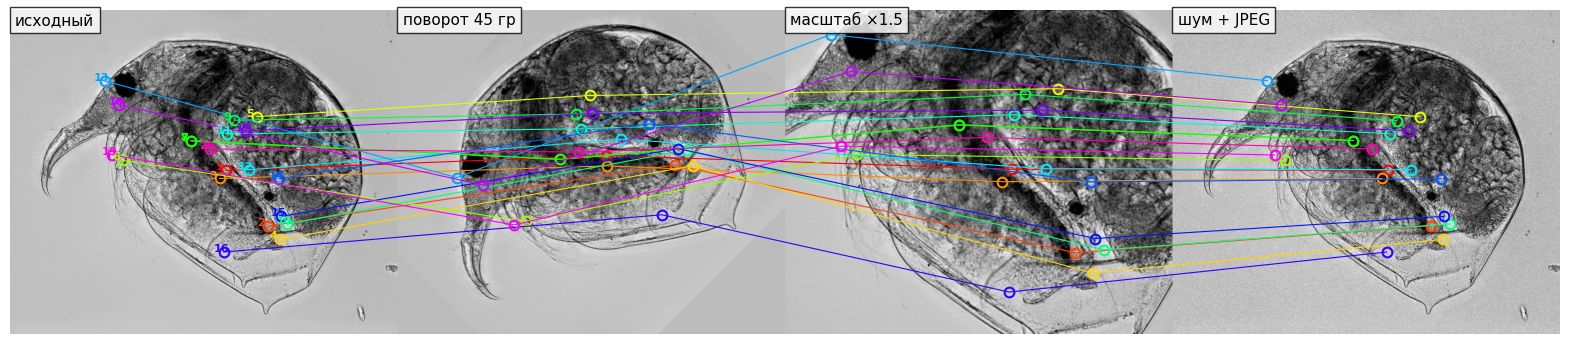

In [152]:
def side_by_side(images, K, tracks, idx, titles, top=20):
    """Выбранные изображения в ряд"""
    tracks = tracks[:top]
    colors = plt.cm.hsv(np.linspace(0, 0.9, len(tracks)))
    w = images[0].shape[1]
    canvas = np.hstack([images[k] for k in idx])
    plt.figure(figsize=(5 * len(idx), 5))
    plt.imshow(canvas, cmap="gray")
    for n, (tr, c) in enumerate(zip(tracks, colors), start=1):
        xs = [K[k][tr[k]].pt[0] + pos * w for pos, k in enumerate(idx)]
        ys = [K[k][tr[k]].pt[1] for k in idx]
        plt.plot(xs, ys, "-", color=c, lw=0.8)
        plt.plot(xs, ys, "o", mfc="none", mec=c, ms=7, mew=1.5)
        plt.text(xs[0] - 22, ys[0], str(n), color=c, fontsize=8, weight="bold")
    for pos, k in enumerate(idx):
        plt.text(pos * w + 10, 30, titles[k], fontsize=11,
                 bbox=dict(facecolor="white", alpha=0.8))
    plt.axis("off")
    plt.show()

side_by_side(views, vkps, tracks, [0, 2, 5, 7], vnames)   # исходный, поворот 45 градусов, масштаб ×1.5, шум + JPEG

Точки с одинаковыми номерами на всех видах попадают в одно и то же место тела, хотя изображение сдвинуто, повернуто, увеличено или ухудшено. Больше всего общих точек на голове у глаза, у основания клюва и на текстуре кишечника и выводковой камеры и это самые контрастные места снимка. На прозрачных частях панциря и на ножках точек почти нет.

## 7. Устойчивость к положению, масштабу, ориентации и качеству

Сопоставляем исходный вид с каждым из остальных и смотрим:
- сколько совпадений найдено
- какая доля из них верная
- какая доля точек исходного вида нашлась снова

In [153]:
rows = []
for k in range(1, len(views)):
    _, _, inliers = match_pair(0, k, vkps, vdescs)
    ok = sum(np.linalg.norm(Ms[k] @ [*vkps[0][m.queryIdx].pt, 1] - vkps[k][m.trainIdx].pt) < 5
             for m in inliers)
    rows.append([vnames[k], len(vkps[k]), len(inliers),
                 f"{100 * ok / max(len(inliers), 1):.0f}%",
                 f"{100 * len(inliers) / len(vkps[0]):.0f}%"])
pd.DataFrame(rows, columns=["вид", "точек", "совпадений с исходным", "верных",
                            "найдено снова (доля точек исходного)"])

,вид,точек,совпадений с исходным,верных,найдено снова (доля точек исходного)
0,сдвиг,4427,4405,100%,98%
1,поворот 45 гр,5412,3179,100%,71%
2,поворот 90 гр,6039,3108,100%,69%
3,масштаб ×0.6,1306,811,100%,18%
4,масштаб ×1.5,11058,2543,100%,57%
5,размытие,1046,358,100%,8%
6,шум + JPEG,4544,1922,100%,43%


По результатам имеем такие итоги
- Сдвиг почти не влияет, снова найдено 98 % точек.
- При повороте на 45 гр и 90 гр находится около 70 % точек. SIFT устойчив к повороту, потому что для каждой точки вычисляет её направление и строит дескриптор относительно него. Часть точек теряется у краев кадра и из-за интерполяции при повороте.
- При увеличении х1.5 находится 57 % точек, при уменьшении х0.6 только 18 %. При уменьшении мелкие детали пропадают, и точки на них исчезают.
- Шум и сжатие JPEG снижают долю до 43 %, а размытие сильнее всего, до 8 %. SIFT опирается на мелкие перепады яркости, а размытие их убирает.

Во всех случаях найденные совпадения верные. Ухудшение условий уменьшает число найденных точек, но не приводит к ошибочным совпадениям.

## Ход работы

1. В качестве метода выбран SIFT с параметрами по умолчанию, также был рассмотрен ORB для сравнения по числу точек.

2. Для фильтрации совпадений использованы тест Лоу с порогом 0.75, взаимная проверка и RANSAC с порогом 10 пикселей и минимумом 6 пар.

3. Снимки уменьшены до 800 пикселей по длинной стороне, так как на исходных SIFT находил десятки тысяч точек.

4. Снимки №2, №3, №5 отражены по горизонтали, так как SIFT не устойчив к зеркальному отражению.

5. Перебраны 5 параметров SIFT на паре с известным преобразованием, по результатам оставлены значения по умолчанию.

6. Добавлена взаимная проверка, так как без неё RANSAC принимал ложные совпадения.

7. На 6 снимках общих точек не найдено, поэтому алгоритм проверен на 8 видах одной особи с известным преобразованием.

8. В итоге на 6 разных особях 0 общих точек, а на 8 видах одной особи 105 общих точек, и все они верные.

## 8. Выводы

1. SIFT нашёл на снимках №1 – №6: 2530, 4488, 3738, 7326, 4150 и 107 точек. Меньше всего точек на размытом снимке №6. Для сравнения, ORB нашёл 35–5000 точек, при огрничении в 5000. Параметры SIFT влияют в основном на количество точек. При повышении contrastThreshold и sigma уменьшается их число, а доля верных совпадений при этом почти не меняется. Значения по умолчанию это разумный компромисс.

2. Между снимком №1 и остальными тест Лоу оставляет от 5 до 57 совпадений, взаимная проверка от 0 до 6, а после RANSAC надёжных совпадений нет ни в одной паре. На видах одной особи совпадений сотни и тысячи, и все верные.

3. Для шести снимков нет общих ключевых точек. На снимках разные особи с разной внутренней структурой, т они сняты на разных микроскопах. Для восьми видов одной особи имеем 105 общих точек, и все они верные. Значит, алгоритм поиска общих точек работает правильно, а ноль объясняется данными.

4. Больше всего общих точек на голове у глаза, у основания рострума и на контрастной текстуре кишечника и выводковой камеры. На прозрачном панцире и ножках точек почти нет так как там мало перепадов яркости.

5. SIFT полностью устойчив к сдвигу 98 % точек найдено снова, хорошо устойчив к повороту имеем около 70 % и увеличению 57 %, но хуже к уменьшению где 18 % и шуму 43 %, и сильнее всего страдает от размытия 8 %. При этом все найденные совпадения верные. Главное ограничение метода в этой задаче это не поворот или масштаб, а то, что на снимках разные особи. Локальные дескрипторы описывают индивидуальную текстуру, а не общую форму тела.